# Technology Transition Comparison Across Case Studies

## Analysis of ICEV → BEV Transition in Road Freight Transport

This notebook compares the technology transition (ICEV vs BEV) across multiple case studies with different electricity pricing and network cost configurations.

**Case Studies:**
1. var_var: Variable electricity prices + Variable network costs
2. var_uni: Variable electricity prices + Uniform network costs
3. uni_var: Uniform electricity prices + Variable network costs
4. uni_uni: Uniform electricity prices + Uniform network costs
5. Additional case studies as available

**Key Metrics:**
- Technology split (TKM by ICEV vs BEV)
- BEV adoption rate over time
- Comparison across different pricing scenarios

In [1]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from collections import defaultdict
import seaborn as sns

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (16, 10)
plt.rcParams['font.size'] = 11

## 1. Configuration - Define Case Studies to Compare

In [2]:
# Base paths
base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM")

# Define case studies to compare
# Format: {'label': 'case_directory', ...}
case_studies = {
    'Var Elec + Var Network': 'case_20251110_160304_var_var',
    'Var Elec + Uni Network': 'case_20251110_160335_var_uni',
    'Uni Elec + Var Network': 'case_20251110_160526_uni_var',
    'Uni Elec + Uni Network': 'case_20251110_160604_uni_uni',
    'Reverse Pricing': 'case_20251110_160646_reverse',
    'Rail': 'case_20251124_110438_rail',
}

# Technology colors
tech_colors = {
    'ICEV': '#E67E22',  # Orange
    'BEV': '#27AE60',   # Green
}

print("Case studies to analyze:")
for label, case_dir in case_studies.items():
    case_path = base_path / 'input_data' / case_dir
    if case_path.exists():
        print(f"  ✓ {label:30s} → {case_dir}")
    else:
        print(f"  ✗ {label:30s} → {case_dir} [NOT FOUND]")

Case studies to analyze:
  ✓ Var Elec + Var Network         → case_20251110_160304_var_var
  ✓ Var Elec + Uni Network         → case_20251110_160335_var_uni
  ✓ Uni Elec + Var Network         → case_20251110_160526_uni_var
  ✓ Uni Elec + Uni Network         → case_20251110_160604_uni_uni
  ✓ Reverse Pricing                → case_20251110_160646_reverse
  ✓ Rail                           → case_20251124_110438_rail


## 2. Load Input Data and Results for All Cases

In [3]:
def load_case_data(case_dir):
    """
    Load input data and results for a single case study.
    
    Returns:
        dict: {'input_data': {...}, 'output_data': {...}}
    """
    input_dir = base_path / 'input_data' / case_dir
    results_dir = base_path / 'results' / case_dir
    
    # Find the latest result timestamp for this case
    result_files = list(results_dir.glob(f"{case_dir}_cs_*_f_dict.yaml"))
    if not result_files:
        print(f"  ✗ No results found for {case_dir}")
        return None
    
    # Get the most recent result file
    latest_result = sorted(result_files)[-1]
    result_timestamp = latest_result.stem.replace('_f_dict', '')
    
    print(f"  Loading {case_dir}...")
    print(f"    Result: {result_timestamp}")
    
    # Load input data (all files needed for analysis)
    input_data = {}
    input_files = [
        'Path.yaml', 
        'TechVehicle.yaml', 
        'Mode.yaml', 
        'Model.yaml', 
        'GeographicElement.yaml',
        'Fuel.yaml'
    ]
    for filename in input_files:
        filepath = input_dir / filename
        if filepath.exists():
            with open(filepath, 'r', encoding='utf-8') as f:
                input_data[filename.replace('.yaml', '')] = yaml.safe_load(f)
    
    # Load output data (f_dict and s_dict)
    output_data = {}
    
    # Load f_dict (flow)
    f_file = results_dir / f"{result_timestamp}_f_dict.yaml"
    if f_file.exists():
        with open(f_file, 'r', encoding='utf-8') as f:
            output_data['f'] = yaml.safe_load(f)
    
    # Load s_dict (charging/electricity consumption)
    s_file = results_dir / f"{result_timestamp}_s_dict.yaml"
    if s_file.exists():
        with open(s_file, 'r', encoding='utf-8') as f:
            output_data['s'] = yaml.safe_load(f)
        print(f"    ✓ Loaded {len(output_data['f'])} flows, {len(output_data['s'])} charging entries")
    else:
        print(f"    ✓ Loaded {len(output_data['f'])} flows")
    
    return {
        'input_data': input_data,
        'output_data': output_data,
        'result_timestamp': result_timestamp
    }

# Load all case studies
loaded_cases = {}
print("\n" + "="*80)
print("LOADING CASE STUDIES")
print("="*80)

for label, case_dir in case_studies.items():
    case_data = load_case_data(case_dir)
    if case_data:
        loaded_cases[label] = case_data

print(f"\n✓ Successfully loaded {len(loaded_cases)} case studies")
print("="*80)


LOADING CASE STUDIES
  Loading case_20251110_160304_var_var...
    Result: case_20251110_160304_var_var_cs_2025-11-18_10-44-39
    ✓ Loaded 127618 flows, 1216297 charging entries
  Loading case_20251110_160335_var_uni...
    Result: case_20251110_160335_var_uni_cs_2025-11-18_11-02-15
    ✓ Loaded 127003 flows, 1205872 charging entries
  Loading case_20251110_160526_uni_var...
    Result: case_20251110_160526_uni_var_cs_2025-11-18_11-17-49
    ✓ Loaded 127714 flows, 1219215 charging entries
  Loading case_20251110_160604_uni_uni...
    Result: case_20251110_160604_uni_uni_cs_2025-11-18_11-32-53
    ✓ Loaded 126590 flows, 1185158 charging entries
  Loading case_20251110_160646_reverse...
    Result: case_20251110_160646_reverse_cs_2025-11-18_10-30-55
    ✓ Loaded 127956 flows, 1225549 charging entries
  Loading case_20251124_110438_rail...
    Result: case_20251124_110438_rail_cs_2025-11-24_11-06-53
    ✓ Loaded 135958 flows, 1190913 charging entries

✓ Successfully loaded 6 case studie

## 3. Calculate Technology Split for Each Case Study

In [4]:
def parse_f_key(key_str):
    """
    Parse f_dict key string: (year, (product, odpair, path), (mode, techvehicle), generation)
    
    Example: "(2036, (0, 1232, 1232), (1, 0), 2032)" 
    Returns: {'year': 2036, 'path': 1232, 'mode': 1, 'techvehicle': 0, 'generation': 2032}
    """
    import re
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
    match = re.match(pattern, key_str)
    if match:
        return {
            'year': int(match.group(1)),
            'product': int(match.group(2)),
            'odpair': int(match.group(3)),
            'path': int(match.group(4)),
            'mode': int(match.group(5)),
            'techvehicle': int(match.group(6)),
            'generation': int(match.group(7))
        }
    return None

def calculate_road_technology_split(case_label, case_data):
    """
    Calculate TKM by technology (ICEV vs BEV) within road mode for a single case.
    
    Returns:
        dict: {year: {'ICEV': tkm, 'BEV': tkm}}
    """
    input_data = case_data['input_data']
    output_data = case_data['output_data']
    f_data = output_data['f']
    
    # Load reference data
    paths = {p['id']: p for p in input_data['Path']}
    techvehicles = {tv['id']: tv for tv in input_data['TechVehicle']}
    
    # Initialize
    tech_tkm = {}
    
    # Process flows
    for key_str, flow_value in f_data.items():
        # Parse key string
        parsed = parse_f_key(key_str)
        if not parsed:
            continue
        
        year = parsed['year']
        mode_id = parsed['mode']
        techvehicle_id = parsed['techvehicle']
        path_id = parsed['path']
        
        # Only process road mode (mode_id == 1)
        if mode_id == 1:
            # Get technology name
            tv = techvehicles.get(techvehicle_id)
            if tv and path_id in paths:
                tech_name = tv['name']  # 'ICEV' or 'BEV'
                
                # Convert flow_value to float (YAML may load as string)
                flow = float(flow_value) if isinstance(flow_value, str) else flow_value
                
                # Calculate TKM
                path_length = paths[path_id]['length']
                tkm = flow * path_length
                
                # Store
                if year not in tech_tkm:
                    tech_tkm[year] = {}
                if tech_name not in tech_tkm[year]:
                    tech_tkm[year][tech_name] = 0.0
                tech_tkm[year][tech_name] += tkm
    
    return tech_tkm

# Calculate for all cases
print("\n" + "="*80)
print("CALCULATING TECHNOLOGY SPLITS")
print("="*80)

all_tech_data = {}
for label, case_data in loaded_cases.items():
    print(f"\nProcessing: {label}")
    tech_data = calculate_road_technology_split(label, case_data)
    all_tech_data[label] = tech_data
    
    # Display summary
    if tech_data:
        print(f"  Years: {sorted(tech_data.keys())}")
        for year in sorted(tech_data.keys()):
            total = sum(tech_data[year].values())
            bev_pct = (tech_data[year].get('BEV', 0) / total * 100) if total > 0 else 0
            print(f"    {year}: Total = {total/1e9:8.2f} B tkm, BEV = {bev_pct:5.1f}%")
    else:
        print(f"  WARNING: No data calculated for {label}")

print("\n" + "="*80)
print(f"✓ Technology splits calculated for {len(all_tech_data)} cases")
print("="*80)


CALCULATING TECHNOLOGY SPLITS

Processing: Var Elec + Var Network
  Years: [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]
    2020: Total =     0.03 B tkm, BEV =   0.0%
    2024: Total =     0.03 B tkm, BEV =   0.0%
    2028: Total =     0.03 B tkm, BEV =   2.8%
    2032: Total =     0.03 B tkm, BEV =   2.7%
    2036: Total =     0.03 B tkm, BEV =   2.9%
    2040: Total =     0.04 B tkm, BEV =   3.1%
    2044: Total =     0.04 B tkm, BEV =  12.5%
    2048: Total =     0.04 B tkm, BEV =  20.7%
    2052: Total =     0.04 B tkm, BEV =  31.9%
    2056: Total =     0.04 B tkm, BEV =  46.6%
    2060: Total =     0.01 B tkm, BEV =  85.5%

Processing: Var Elec + Uni Network
  Years: [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]
    2020: Total =     0.03 B tkm, BEV =   0.0%
    2024: Total =     0.03 B tkm, BEV =   0.0%
    2028: Total =     0.03 B tkm, BEV =   2.8%
    2032: Total =     0.03 B tkm, BEV =   2.7%
    2036: Total =     0.03 B tkm, BEV = 

## 4. Visualization 1: Stacked Bar Charts - Technology Split by Case

C:\Users\simuser\AppData\Local\Temp\ipykernel_31780\1322837390.py:46: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()



✓ Saved: technology_split_all_cases.pdf


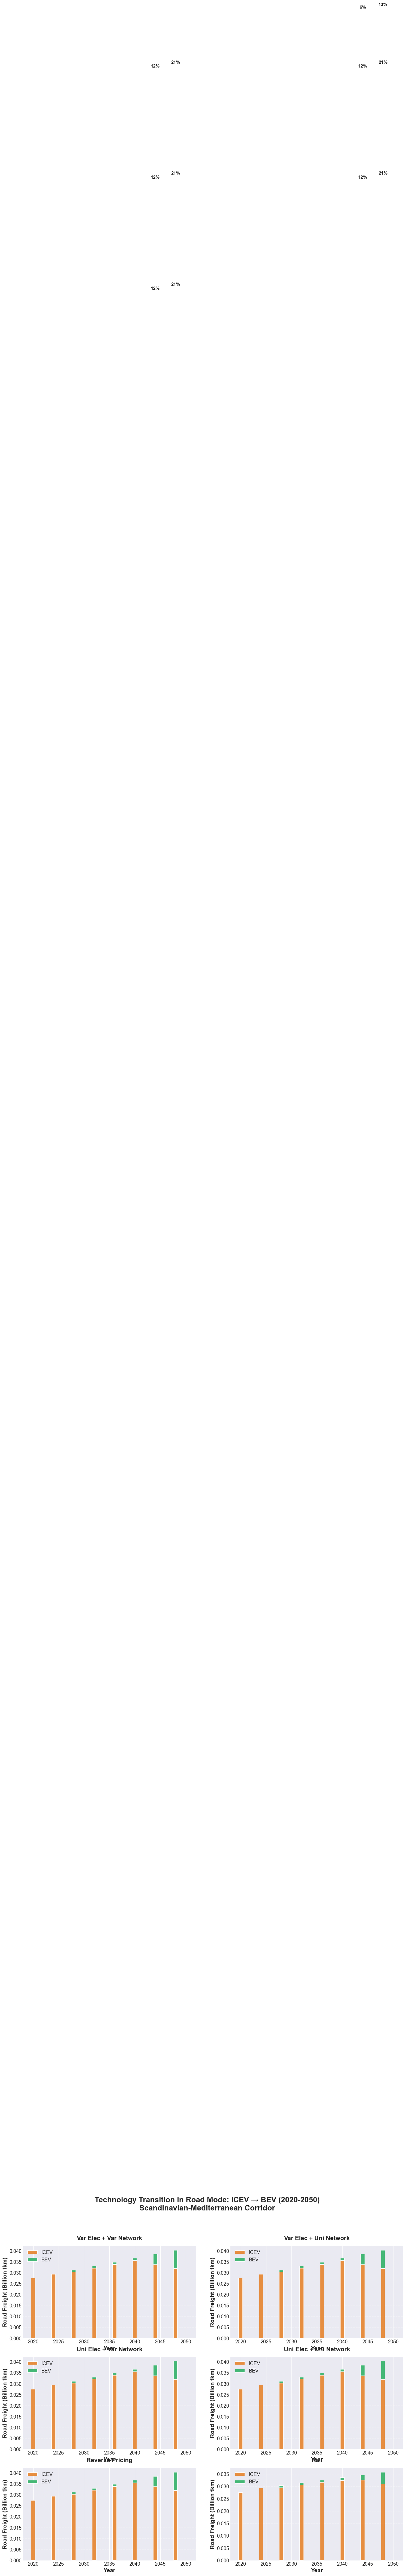

In [5]:
# Create subplot for each case study
n_cases = len(all_tech_data)
n_cols = 2
n_rows = (n_cases + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten() if n_cases > 1 else [axes]

for idx, (label, tech_data) in enumerate(all_tech_data.items()):
    ax = axes[idx]
    
    # Filter years to 2020-2050
    years = [y for y in sorted(tech_data.keys()) if 2020 <= y <= 2050]
    icev_values = [tech_data[year].get('ICEV', 0) / 1e9 for year in years]
    bev_values = [tech_data[year].get('BEV', 0) / 1e9 for year in years]
    
    # Stacked bar chart
    ax.bar(years, icev_values, label='ICEV', color=tech_colors['ICEV'], 
           alpha=0.85, edgecolor='white', linewidth=1.5)
    ax.bar(years, bev_values, bottom=icev_values, label='BEV', 
           color=tech_colors['BEV'], alpha=0.85, edgecolor='white', linewidth=1.5)
    
    ax.set_xlabel('Year', fontsize=15, fontweight='bold')
    ax.set_ylabel('Road Freight (Billion tkm)', fontsize=15, fontweight='bold')
    ax.set_title(f'{label}', fontsize=16, fontweight='bold', pad=15)
    ax.legend(loc='upper left', fontsize=13)
    ax.grid(True, alpha=0.3, axis='y', linestyle='--')
    ax.set_xlim(2018, 2052)  # Add margins
    ax.tick_params(axis='both', labelsize=13)
    
    # Add percentage labels
    for i, year in enumerate(years):
        total = icev_values[i] + bev_values[i]
        if total > 0:
            bev_pct = (bev_values[i] / total * 100)
            if bev_pct > 5:  # Only show if > 5%
                ax.text(year, total + 1, f'{bev_pct:.0f}%', 
                       ha='center', va='bottom', fontsize=12, fontweight='bold')

# Hide unused subplots
for idx in range(n_cases, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Technology Transition in Road Mode: ICEV → BEV (2020-2050)\nScandinavian-Mediterranean Corridor',
             fontsize=20, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('technology_split_all_cases.pdf', dpi=300, bbox_inches='tight')
print("\n✓ Saved: technology_split_all_cases.pdf")
plt.show()

## 5. Visualization 2: BEV Adoption Rate Comparison


✓ Saved: bev_adoption_rate_comparison.pdf


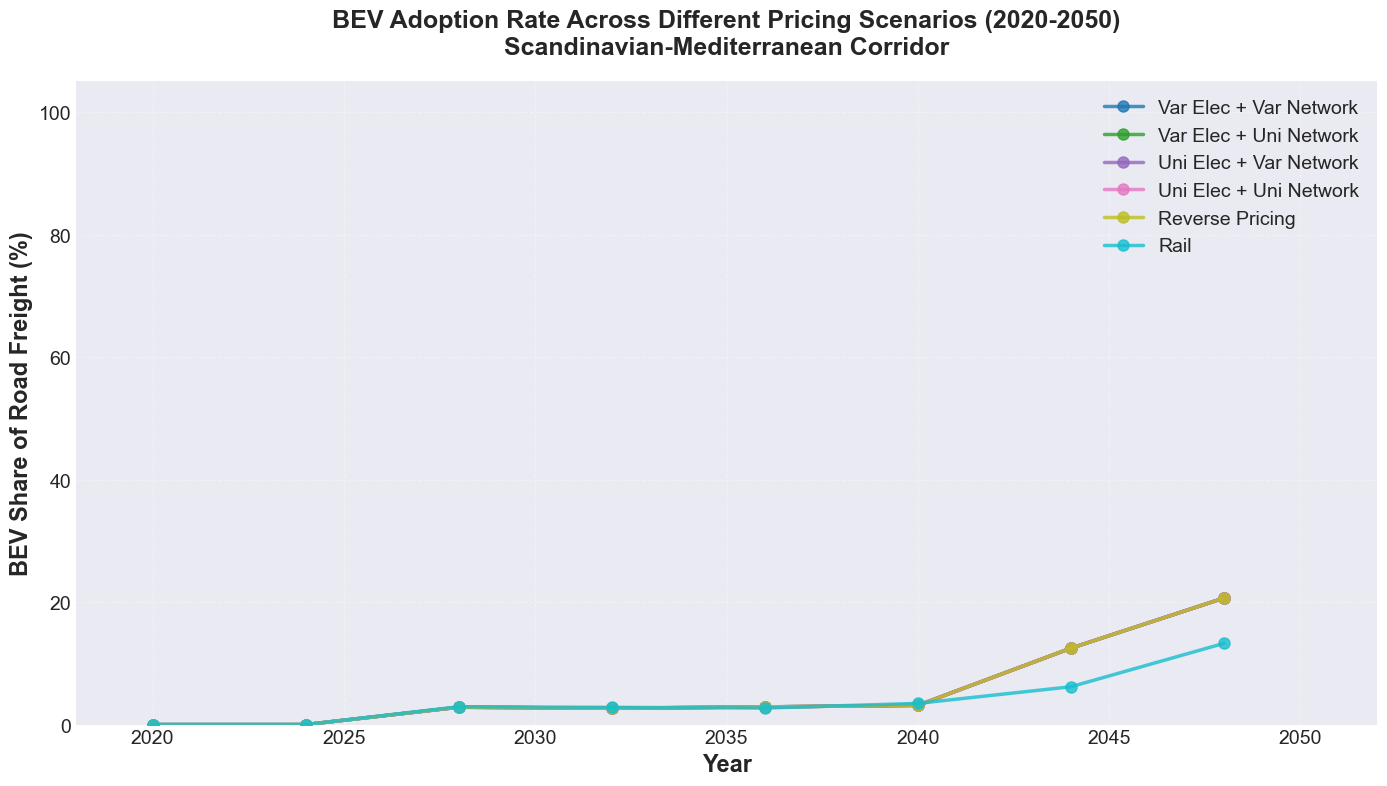

In [6]:
# Calculate BEV share for each case over time
fig, ax = plt.subplots(figsize=(14, 8))

colors = plt.cm.tab10(np.linspace(0, 1, len(all_tech_data)))

for idx, (label, tech_data) in enumerate(all_tech_data.items()):
    # Filter years to 2020-2050
    years = [y for y in sorted(tech_data.keys()) if 2020 <= y <= 2050]
    bev_share = []
    
    for year in years:
        total = sum(tech_data[year].values())
        bev_pct = (tech_data[year].get('BEV', 0) / total * 100) if total > 0 else 0
        bev_share.append(bev_pct)
    
    ax.plot(years, bev_share, marker='o', linewidth=2.5, markersize=8, 
            label=label, color=colors[idx], alpha=0.8)

ax.set_xlabel('Year', fontsize=17, fontweight='bold')
ax.set_ylabel('BEV Share of Road Freight (%)', fontsize=17, fontweight='bold')
ax.set_title('BEV Adoption Rate Across Different Pricing Scenarios (2020-2050)\nScandinavian-Mediterranean Corridor',
             fontsize=18, fontweight='bold', pad=20)
ax.legend(loc='best', fontsize=14, framealpha=0.95)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_ylim(0, 105)
ax.set_xlim(2018, 2052)  # Add margins
ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.savefig('bev_adoption_rate_comparison.pdf', dpi=300, bbox_inches='tight')
print("\n✓ Saved: bev_adoption_rate_comparison.pdf")
plt.show()

## 6. Visualization 3: Side-by-Side Comparison for Specific Years


✓ Saved: technology_comparison_by_year.pdf


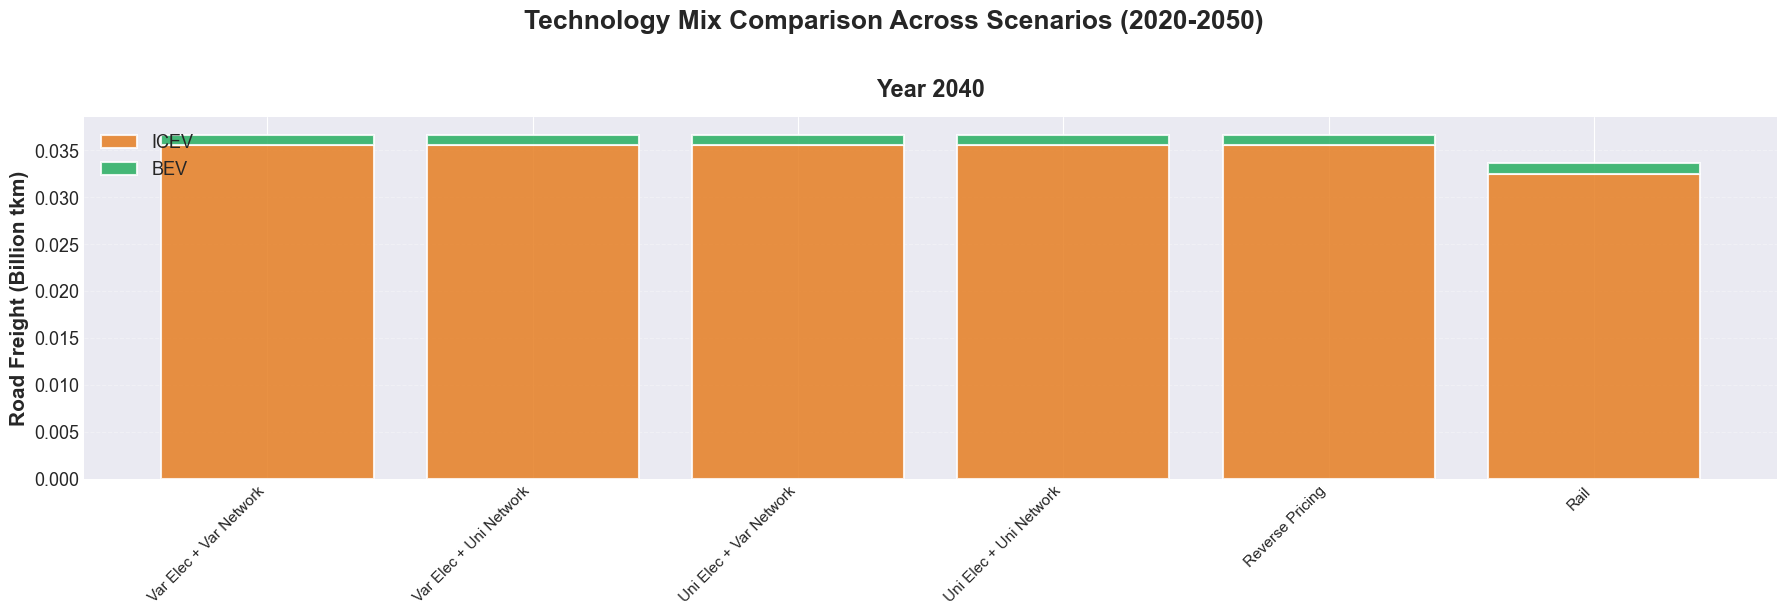

In [7]:
# Select years to compare (within 2020-2050 range)
compare_years = [2030, 2040, 2050]

# Filter to only include years that exist in the data and are within range
available_years = set()
for tech_data in all_tech_data.values():
    available_years.update([y for y in tech_data.keys() if 2020 <= y <= 2050])

compare_years = [y for y in compare_years if y in available_years]

if not compare_years:
    print("No years available for comparison in 2020-2050 range")
else:
    fig, axes = plt.subplots(1, len(compare_years), figsize=(18, 6))
    if len(compare_years) == 1:
        axes = [axes]
    
    for idx, year in enumerate(compare_years):
        ax = axes[idx]
        
        case_labels = []
        icev_vals = []
        bev_vals = []
        
        for label, tech_data in all_tech_data.items():
            if year in tech_data:
                case_labels.append(label)
                icev_vals.append(tech_data[year].get('ICEV', 0) / 1e9)
                bev_vals.append(tech_data[year].get('BEV', 0) / 1e9)
        
        x_pos = np.arange(len(case_labels))
        
        ax.bar(x_pos, icev_vals, label='ICEV', color=tech_colors['ICEV'], 
               alpha=0.85, edgecolor='white', linewidth=1.5)
        ax.bar(x_pos, bev_vals, bottom=icev_vals, label='BEV', 
               color=tech_colors['BEV'], alpha=0.85, edgecolor='white', linewidth=1.5)
        
        ax.set_xticks(x_pos)
        ax.set_xticklabels(case_labels, rotation=45, ha='right', fontsize=11)
        ax.set_ylabel('Road Freight (Billion tkm)', fontsize=15, fontweight='bold')
        ax.set_title(f'Year {year}', fontsize=17, fontweight='bold', pad=15)
        ax.tick_params(axis='y', labelsize=13)
        if idx == 0:
            ax.legend(loc='upper left', fontsize=13)
        ax.grid(True, alpha=0.3, axis='y', linestyle='--')
    
    plt.suptitle('Technology Mix Comparison Across Scenarios (2020-2050)',
                 fontsize=19, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('technology_comparison_by_year.pdf', dpi=300, bbox_inches='tight')
    print("\n✓ Saved: technology_comparison_by_year.pdf")
    plt.show()

## 7. Summary Statistics Table

In [8]:
# Create summary dataframe (2020-2050 range)
summary_data = []

for label, tech_data in all_tech_data.items():
    # Filter years to 2020-2050
    years = [y for y in sorted(tech_data.keys()) if 2020 <= y <= 2050]
    
    if not years:
        continue
    
    # First year
    first_year = years[0]
    first_total = sum(tech_data[first_year].values())
    first_bev_pct = (tech_data[first_year].get('BEV', 0) / first_total * 100) if first_total > 0 else 0
    
    # Last year
    last_year = years[-1]
    last_total = sum(tech_data[last_year].values())
    last_bev_pct = (tech_data[last_year].get('BEV', 0) / last_total * 100) if last_total > 0 else 0
    
    summary_data.append({
        'Case Study': label,
        f'{first_year} Total (B tkm)': f'{first_total/1e9:.2f}',
        f'{first_year} BEV %': f'{first_bev_pct:.1f}%',
        f'{last_year} Total (B tkm)': f'{last_total/1e9:.2f}',
        f'{last_year} BEV %': f'{last_bev_pct:.1f}%',
        'BEV Growth': f'{last_bev_pct - first_bev_pct:.1f} pp',
    })

df_summary = pd.DataFrame(summary_data)

print("\\n" + "="*120)
print("SUMMARY: TECHNOLOGY TRANSITION ACROSS CASE STUDIES (2020-2050)")
print("="*120)
print(df_summary.to_string(index=False))
print("="*120)

# Save to CSV
df_summary.to_csv('technology_transition_summary.csv', index=False)
print("\\n✓ Saved: technology_transition_summary.csv")

\n========================================================================================================================
SUMMARY: TECHNOLOGY TRANSITION ACROSS CASE STUDIES (2020-2050)
            Case Study 2020 Total (B tkm) 2020 BEV % 2048 Total (B tkm) 2048 BEV % BEV Growth
Var Elec + Var Network               0.03       0.0%               0.04      20.7%    20.7 pp
Var Elec + Uni Network               0.03       0.0%               0.04      20.7%    20.7 pp
Uni Elec + Var Network               0.03       0.0%               0.04      20.7%    20.7 pp
Uni Elec + Uni Network               0.03       0.0%               0.04      20.7%    20.7 pp
       Reverse Pricing               0.03       0.0%               0.04      20.7%    20.7 pp
                  Rail               0.03       0.0%               0.04      13.3%    13.3 pp
\n✓ Saved: technology_transition_summary.csv


## 8. Export Data for External Analysis

In [9]:
# Export detailed year-by-year data for all cases (2020-2050)
export_data = []

for label, tech_data in all_tech_data.items():
    # Filter years to 2020-2050
    years = [y for y in sorted(tech_data.keys()) if 2020 <= y <= 2050]
    
    for year in years:
        total = sum(tech_data[year].values())
        icev_tkm = tech_data[year].get('ICEV', 0)
        bev_tkm = tech_data[year].get('BEV', 0)
        
        export_data.append({
            'Case_Study': label,
            'Year': year,
            'ICEV_tkm': icev_tkm,
            'BEV_tkm': bev_tkm,
            'Total_tkm': total,
            'ICEV_share_pct': (icev_tkm / total * 100) if total > 0 else 0,
            'BEV_share_pct': (bev_tkm / total * 100) if total > 0 else 0,
        })

df_export = pd.DataFrame(export_data)
df_export.to_csv('technology_data_detailed.csv', index=False)
print("\\n✓ Saved: technology_data_detailed.csv")
print(f"  {len(df_export)} rows exported (years 2020-2050)")

\n✓ Saved: technology_data_detailed.csv
  48 rows exported (years 2020-2050)


## 9. Electricity Consumption by Latitude - Spatial Analysis

## 9. Electricity Consumption by Latitude - Spatial Analysis

This section analyzes how electricity consumption for BEV charging varies across different latitudes (North-South gradient) in the Scandinavian-Mediterranean corridor.

In [10]:
# Prepare data structure for electricity consumption by latitude analysis
# The function expects loaded_runs dictionary with case_dir as keys

# Convert loaded_cases to loaded_runs format (case_dir as key)
loaded_runs = {}
case_dir_to_label = {}  # Reverse mapping

for label, case_data in loaded_cases.items():
    case_dir = case_studies[label]
    loaded_runs[case_dir] = {
        'input_data': case_data['input_data'],
        'output_data': case_data['output_data']
    }
    case_dir_to_label[case_dir] = label

print(f"\n{'='*80}")
print(f"PREPARED DATA FOR LATITUDE ANALYSIS")
print(f"{'='*80}")
print(f"Available case studies: {len(loaded_runs)}")
for case_dir in loaded_runs.keys():
    print(f"  - {case_dir}")
print(f"{'='*80}\n")


PREPARED DATA FOR LATITUDE ANALYSIS
Available case studies: 6
  - case_20251110_160304_var_var
  - case_20251110_160335_var_uni
  - case_20251110_160526_uni_var
  - case_20251110_160604_uni_uni
  - case_20251110_160646_reverse
  - case_20251124_110438_rail




ELECTRICITY CONSUMPTION BY LATITUDE ANALYSIS
Year: 2040
Analyzing 4 case studies

CALCULATING ELECTRICITY CONSUMPTION BY LATITUDE (Year: 2040)

Processing: case_20251110_160304_var_var
  Found 81 NUTS2 regions
  Electricity fuel IDs: [0]
  Electricity infrastructure types: {}
  Regions with BEV traffic: 80
  Electricity range: 0.0 to 0.2 GWh
  Total electricity demand: 1.5 GWh

Processing: case_20251110_160335_var_uni
  Found 81 NUTS2 regions
  Electricity fuel IDs: [0]
  Electricity infrastructure types: {}
  Regions with BEV traffic: 80
  Electricity range: 0.0 to 0.2 GWh
  Total electricity demand: 1.6 GWh

Processing: case_20251110_160526_uni_var
  Found 81 NUTS2 regions
  Electricity fuel IDs: [0]
  Electricity infrastructure types: {}
  Regions with BEV traffic: 80
  Electricity range: 0.0 to 0.1 GWh
  Total electricity demand: 1.5 GWh

Processing: case_20251110_160604_uni_uni
  Found 81 NUTS2 regions
  Electricity fuel IDs: [0]
  Electricity infrastructure types: {}
  Regions w

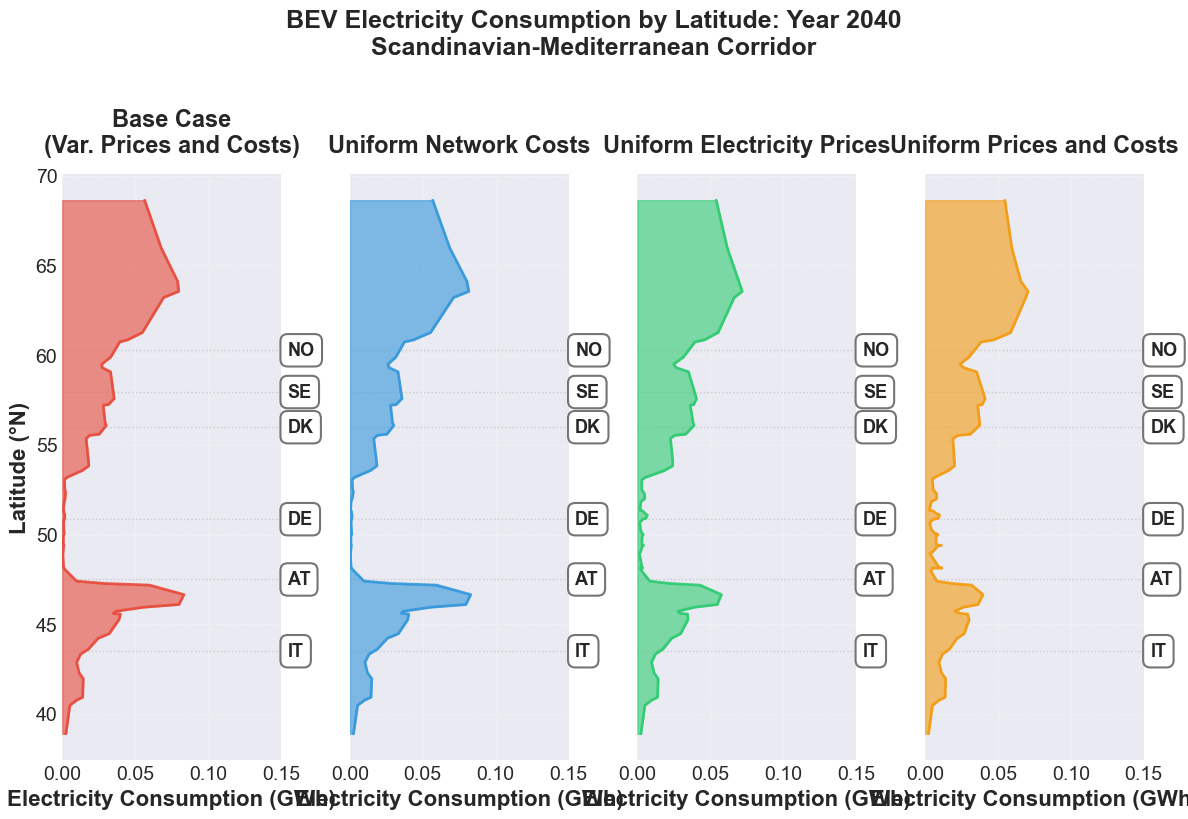


✓ Electricity consumption by latitude plot created


In [11]:
%load_ext autoreload
%autoreload 2

from electricity_consumption_by_latitude import plot_electricity_by_latitude_4cases, analyze_electricity_by_latitude_band

# Select case studies for comparison (excluding Reverse Uniformity)
selected_case_dirs = [
    "case_20251110_160304_var_var",
    "case_20251110_160335_var_uni",
    "case_20251110_160526_uni_var",
    "case_20251110_160604_uni_uni"
]

# Define labels for the plot
case_labels = {
    "case_20251110_160304_var_var": "Base Case\n(Var. Prices and Costs)",
    "case_20251110_160335_var_uni": "Uniform Network Costs",
    "case_20251110_160526_uni_var": "Uniform Electricity Prices",
    "case_20251110_160604_uni_uni": "Uniform Prices and Costs"
}

print(f"\n{'='*80}")
print(f"ELECTRICITY CONSUMPTION BY LATITUDE ANALYSIS")
print(f"{'='*80}")
print(f"Year: 2040")
print(f"Analyzing {len(selected_case_dirs)} case studies")
print(f"{'='*80}\n")

# Create electricity consumption plot for 2040
elec_data = plot_electricity_by_latitude_4cases(
    loaded_runs,
    selected_case_dirs,
    year=2040,
    case_labels=case_labels,
    country_centroids_csv='country_centroids.csv'
)

print("\n✓ Electricity consumption by latitude plot created")

In [12]:
# Print statistics by latitude band for each case
print(f"\n{'='*80}")
print(f"STATISTICS BY LATITUDE BAND (Year 2040)")
print(f"{'='*80}")

# Use the same case list as the visualization (excluding Reverse Uniformity)
selected_case_dirs = [
    "case_20251110_160304_var_var",
    "case_20251110_160335_var_uni",
    "case_20251110_160526_uni_var",
    "case_20251110_160604_uni_uni"
]

case_labels = {
    "case_20251110_160304_var_var": "Base Case\n(Var. Prices and Costs)",
    "case_20251110_160335_var_uni": "Uniform Network Costs",
    "case_20251110_160526_uni_var": "Uniform Electricity Prices",
    "case_20251110_160604_uni_uni": "Uniform Prices and Costs"
}

for case_dir in selected_case_dirs:
    if case_dir in elec_data:
        label = case_labels.get(case_dir, case_dir)
        print(f"\n{label}:")
        analyze_electricity_by_latitude_band(elec_data[case_dir])

print(f"\n{'='*80}")


STATISTICS BY LATITUDE BAND (Year 2040)

Base Case
(Var. Prices and Costs):
Latitude Band           # Regions  Electricity (GWh)
------------------------------------------------------------
35°N - 40°N                   1                0.0
40°N - 45°N                  10                0.2
45°N - 50°N                  24                0.5
50°N - 55°N                  25                0.1
55°N - 60°N                  12                0.3
60°N - 65°N                   6                0.4
65°N - 70°N                   2                0.1

Uniform Network Costs:
Latitude Band           # Regions  Electricity (GWh)
------------------------------------------------------------
35°N - 40°N                   1                0.0
40°N - 45°N                  10                0.2
45°N - 50°N                  24                0.5
50°N - 55°N                  25                0.1
55°N - 60°N                  12                0.3
60°N - 65°N                   6                0.4
65°N - 7

### Interpretation

The electricity consumption by latitude analysis reveals:

1. **North-South Gradient**: How BEV charging demand varies across the Scandinavian-Mediterranean corridor
2. **Regional Hotspots**: Which latitude bands show highest electricity consumption for transport
3. **Scenario Sensitivity**: How different pricing and cost configurations affect spatial distribution of charging

This spatial analysis is crucial for:
- Infrastructure planning and investment prioritization
- Understanding grid impacts by region
- Identifying potential bottlenecks in the charging network

### Two-Case Narrow Latitude Comparison

Overlapping curves showing Base Case vs. Uniform Prices and Costs with delta analysis.

TWO-CASE LATITUDE COMPARISON (Year: 2040)
  Found 81 NUTS2 regions
  Electricity fuel IDs: [0]
  Electricity infrastructure types: {}
  Found 81 NUTS2 regions
  Electricity fuel IDs: [0]
  Electricity infrastructure types: {}

Base Case:
  Regions: 80
  Total: 1.55 GWh

Uniform Charging prices:
  Regions: 80
  Total: 1.55 GWh

[OK] Narrow latitude comparison saved as 'latitude_comparison_2040.svg'


<string>:80: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.


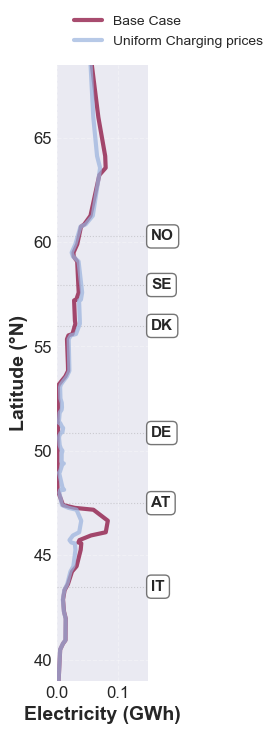


DELTA ANALYSIS: Energy Difference by Latitude
Delta = Base Case - Uniform Charging prices

Latitude Base Case (GWh) Uniform Charging prices (GWh) Delta (GWh)
  43.6°N           0.037                         0.036      +0.001
  44.5°N           0.055                         0.051      +0.005
  45.6°N           0.112                         0.080      +0.032
  45.6°N           0.009                         0.005      +0.003
  46.1°N           0.136                         0.069      +0.066
  46.7°N           0.191                         0.055      +0.136
  47.2°N           0.015                         0.047      -0.032
  48.1°N           0.002                         0.000      +0.002
  48.1°N           0.003                         0.043      -0.041
  49.4°N           0.004                         0.040      -0.037
  50.0°N           0.002                         0.026      -0.025
  50.1°N           0.003                         0.013      -0.010
  50.7°N           0.001             

In [23]:
%reload_ext autoreload
%autoreload 2

from electricity_consumption_by_latitude import plot_latitude_comparison_two_cases

# Compare Base Case vs. Uniform Prices and Costs
case1 = "case_20251110_160304_var_var"  # Base Case
case2 = "case_20251110_160604_uni_uni"  # Uniform Prices and Costs

narrow_results = plot_latitude_comparison_two_cases(
    loaded_runs,
    case1_name=case1,
    case2_name=case2,
    case1_label="Base Case",
    case2_label="Uniform Charging prices",
    year=2040,
    country_centroids_csv="country_centroids.csv"
)

print("OK] Narrow latitude comparison created with delta analysis")

## 10. Border Region Electricity Analysis - Southern Border

This section analyzes electricity consumption in the southern border region (Germany-Austria-Italy Alps Crossing) comparing across different case studies.

In [24]:
import importlib
import border_electricity_analysis
importlib.reload(border_electricity_analysis)
from border_electricity_analysis import plot_border_electricity_comparison, create_summary_table

print("[OK] Border electricity analysis module loaded")

[OK] Border electricity analysis module loaded



BORDER ELECTRICITY ANALYSIS
Years: 2036 and 2044
Analyzing 5 case studies

SOUTHERN BORDER ELECTRICITY ANALYSIS (Years: [2036, 2044])

Southern Border: Germany-Austria-Italy (Alps Crossing)

Regions included:
  AT: AT31, AT32, AT33, AT34
  IT: ITH1, ITH3
  DE: DE14, DE21, DE22, DE27, DEF0

YEAR 2036

Processing: case_20251110_160304_var_var
  Electricity consumption by country:
    AT: 0.50 GWh
    IT: 0.12 GWh
    DE: 0.01 GWh
  Total: 0.63 GWh

Processing: case_20251110_160335_var_uni
  Electricity consumption by country:
    AT: 0.55 GWh
    IT: 0.11 GWh
    DE: 0.00 GWh
  Total: 0.66 GWh

Processing: case_20251110_160526_uni_var
  Electricity consumption by country:
    AT: 0.03 GWh
    IT: 0.37 GWh
    DE: 0.01 GWh
  Total: 0.41 GWh

Processing: case_20251110_160604_uni_uni
  Electricity consumption by country:
    AT: 0.07 GWh
    IT: 0.19 GWh
    DE: 0.07 GWh
  Total: 0.33 GWh

Processing: case_20251124_110438_rail
  Electricity consumption by country:
    AT: 0.47 GWh
    IT: 

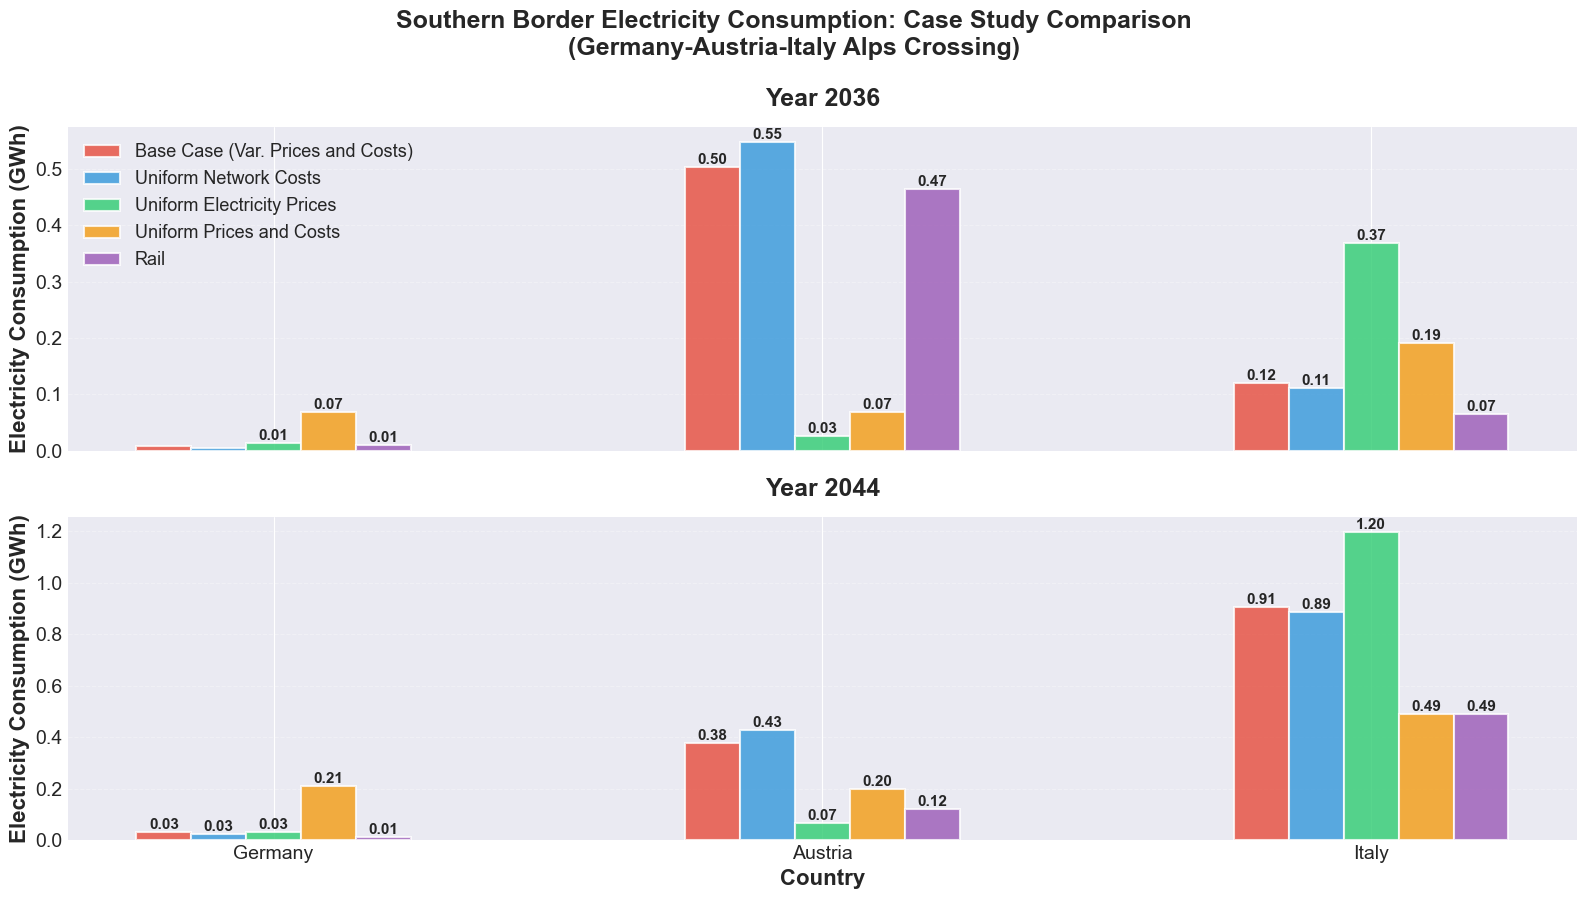


[OK] Border electricity comparison plot created (vertically stacked layout)


In [25]:
# Select case studies for border analysis (excluding Reverse Uniformity, including Rail)
border_case_studies = [
    "case_20251110_160304_var_var",
    "case_20251110_160335_var_uni",
    "case_20251110_160526_uni_var",
    "case_20251110_160604_uni_uni",
    "case_20251124_110438_rail"
]

# Define labels (without line breaks for cleaner display)
border_case_labels = {
    "case_20251110_160304_var_var": "Base Case (Var. Prices and Costs)",
    "case_20251110_160335_var_uni": "Uniform Network Costs",
    "case_20251110_160526_uni_var": "Uniform Electricity Prices",
    "case_20251110_160604_uni_uni": "Uniform Prices and Costs",
    "case_20251124_110438_rail": "Rail"
}

print(f"\n{'='*80}")
print("BORDER ELECTRICITY ANALYSIS")
print(f"{'='*80}")
print(f"Years: 2036 and 2044")
print(f"Analyzing {len(border_case_studies)} case studies")
print(f"{'='*80}\n")

# Create comparison plot (will automatically use years 2036 and 2044)
border_results = plot_border_electricity_comparison(
    loaded_runs,
    border_case_studies,
    year=2040,  # Ignored, function uses fixed years 2036 and 2044
    case_labels=border_case_labels
)

print("\n[OK] Border electricity comparison plot created (vertically stacked layout)")

In [28]:
# Create and display summary table
print(f"\n{'='*80}")
print("BORDER ELECTRICITY CONSUMPTION SUMMARY TABLE")
print(f"{'='*80}\n")

border_df = create_summary_table(border_results, border_case_labels)
print(f"\n{'='*80}")

# Save to CSV
border_df.to_csv("border_electricity_summary_2036_2044.csv", index=False)
print("\n[OK] Border electricity summary saved to border_electricity_summary_2036_2044.csv")


BORDER ELECTRICITY CONSUMPTION SUMMARY TABLE


SUMMARY TABLE: Southern Border Electricity Consumption (GWh)

Year 2036
                       Case Study  Germany (DE)  Austria (AT)  Italy (IT)    Total
Base Case (Var. Prices and Costs)      0.007548      0.504153    0.119916 0.631617
            Uniform Network Costs      0.003664      0.547400    0.110836 0.661900
       Uniform Electricity Prices      0.013211      0.026080    0.368544 0.407835
         Uniform Prices and Costs      0.068353      0.068692    0.190463 0.327508
                             Rail      0.010629      0.465339    0.065378 0.541346

Year 2044
                       Case Study  Germany (DE)  Austria (AT)  Italy (IT)    Total
Base Case (Var. Prices and Costs)      0.034409      0.379217    0.905337 1.318962
            Uniform Network Costs      0.025466      0.429529    0.885523 1.340518
       Uniform Electricity Prices      0.030861      0.067137    1.195806 1.293804
         Uniform Prices and Costs      

### Interpretation

The border region electricity analysis reveals:

1. **Regional Distribution**: How BEV charging demand varies across Austria, Italy, and Germany in the Alps crossing region
2. **Scenario Comparison**: Impact of different pricing and cost configurations on charging patterns in border regions
3. **Infrastructure Planning**: Critical insights for cross-border charging infrastructure deployment

This analysis is crucial for:
- Coordinating cross-border infrastructure investments
- Understanding the impact of policy harmonization vs. differentiation
- Planning grid capacity expansions in international transit corridors

### Interpretation

The load reallocation analysis reveals:

1. **Total Redistribution Magnitude**: How much freight gets routed differently across all paths compared to the base case (sum of absolute differences)
2. **Scenario Sensitivity**: Which pricing/cost configurations cause the most significant rerouting of freight
3. **Temporal Evolution**: How reallocation patterns change over time as technology transitions progress

**Key Metric**: Total Absolute Reallocation = Σ|load_case[path] - load_base[path]|
- Measures total magnitude of route changes regardless of direction
- Both increases and decreases on specific paths contribute to the sum
- Higher values indicate more significant rerouting compared to base case

This analysis is crucial for:
- Understanding the stability of routing patterns across scenarios
- Identifying which policy levers cause the most significant network reorganization
- Planning for infrastructure flexibility to accommodate potential route shifts

In [29]:
# Summary table of load reallocation
print("\n" + "="*100)
print("SUMMARY: TOTAL LOAD REALLOCATION vs. BASE CASE (Billion tkm)")
print("="*100)

# Create DataFrame
realloc_table_data = []

for label, realloc_data in reallocation_results.items():
    row = {'Case Study': label}
    for year in sorted(realloc_data.keys()):
        row[str(year)] = f"{realloc_data[year]:.4f}"
    realloc_table_data.append(row)

df_realloc = pd.DataFrame(realloc_table_data)

# Display
print("\n" + df_realloc.to_string(index=False))
print("\n" + "="*100)

# Save to CSV
df_realloc.to_csv('load_reallocation_vs_base_case.csv', index=False)
print("\n✓ Saved: load_reallocation_vs_base_case.csv")

# Calculate and display average reallocation per case
print("\n" + "="*100)
print("AVERAGE REALLOCATION PER CASE (2020-2048)")
print("="*100)

avg_realloc = []
for label, realloc_data in reallocation_results.items():
    avg_val = np.mean(list(realloc_data.values()))
    avg_realloc.append({
        'Case Study': label,
        'Average Reallocation (B tkm)': f"{avg_val:.4f}"
    })

df_avg = pd.DataFrame(avg_realloc)
df_avg = df_avg.sort_values('Average Reallocation (B tkm)', ascending=False)
print("\n" + df_avg.to_string(index=False))
print("="*100)


SUMMARY: TOTAL LOAD REALLOCATION vs. BASE CASE (Billion tkm)


NameError: name 'reallocation_results' is not defined


✓ Saved: charging_reallocation_comparison_2040.svg


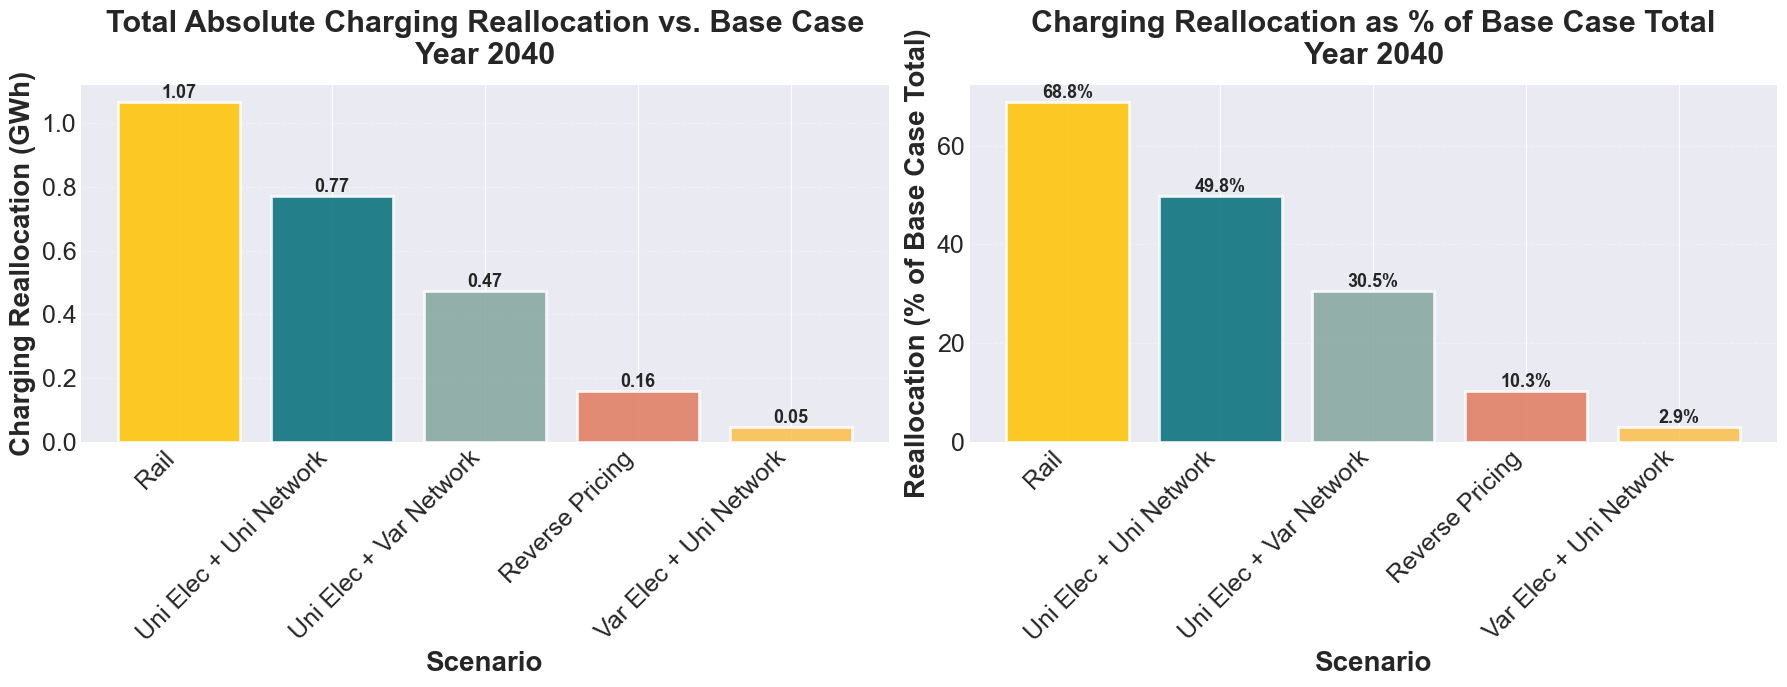


✓ Saved: charging_reallocation_time_series.pdf


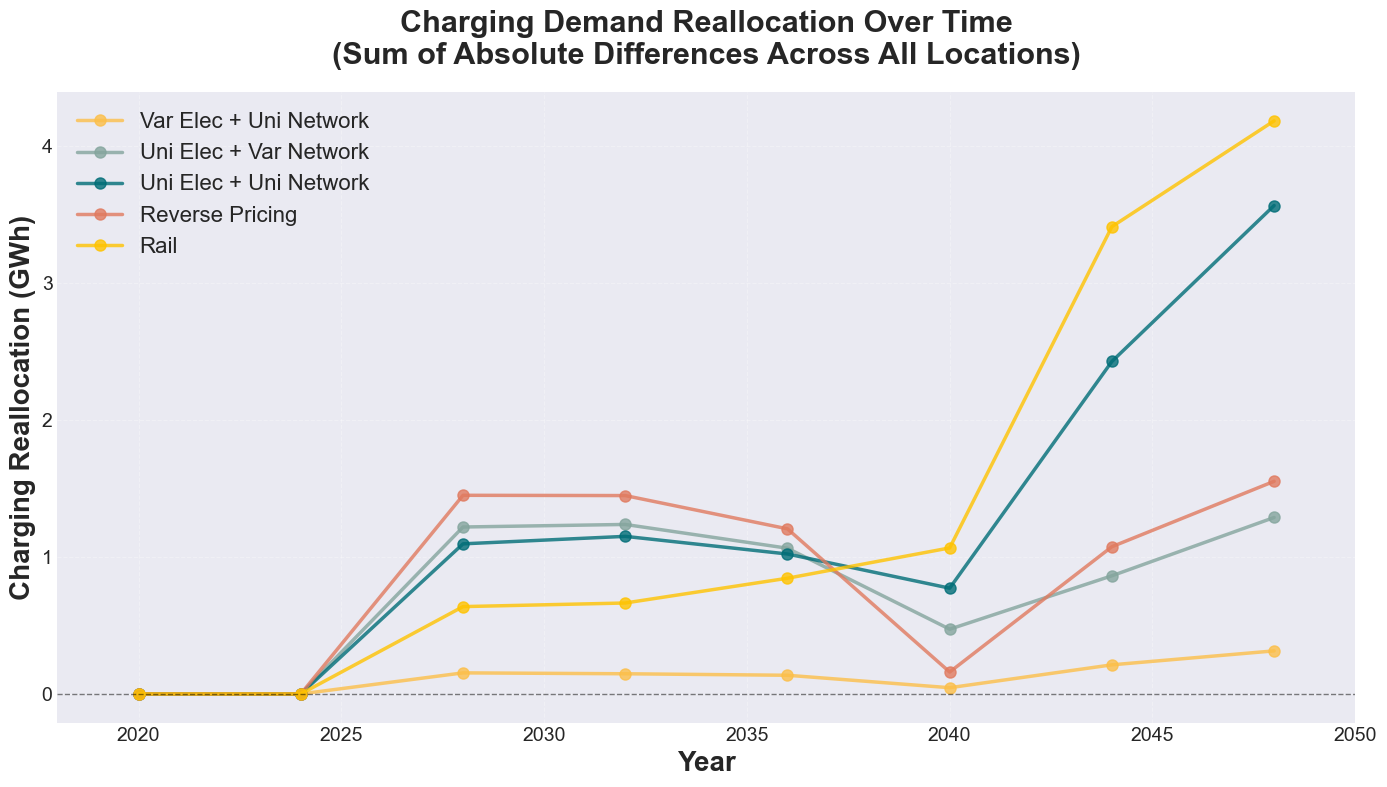

In [46]:
# Define colors for each case study (customize these!)
case_colors = {
    'Var Elec + Uni Network': '#fcbf49',      # Blue
    'Uni Elec + Var Network': '#84a59d',      # Red
    'Uni Elec + Uni Network': '#006d77',      # Green
    'Reverse Pricing': '#e07a5f',              # Orange
    'Rail': '#ffc300'                          # Purple
}

# Visualization 1: Bar plot for a specific year (2040)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Select year for comparison
comparison_year = 2040

# Prepare data
case_labels_short = []
realloc_values_gwh = []
realloc_values_pct = []

# Calculate base case total for percentage
base_charging_comp = calculate_charging_by_location(base_case_data, comparison_year)
base_total_gwh = sum(base_charging_comp.values()) / 1e6

for label, realloc_data in reallocation_results.items():
    case_labels_short.append(label)
    realloc_gwh = realloc_data[comparison_year]
    realloc_values_gwh.append(realloc_gwh)
    realloc_values_pct.append((realloc_gwh / base_total_gwh) * 100)

# Sort by reallocation amount (descending)
sorted_indices = sorted(range(len(realloc_values_gwh)), key=lambda i: realloc_values_gwh[i], reverse=True)
case_labels_sorted = [case_labels_short[i] for i in sorted_indices]
realloc_gwh_sorted = [realloc_values_gwh[i] for i in sorted_indices]
realloc_pct_sorted = [realloc_values_pct[i] for i in sorted_indices]

# Get colors in sorted order
colors_sorted = [case_colors.get(label, '#95A5A6') for label in case_labels_sorted]

x_pos = np.arange(len(case_labels_sorted))

# Plot 1: Absolute values (GWh)
bars1 = ax1.bar(x_pos, realloc_gwh_sorted, color=colors_sorted, 
                alpha=0.85, edgecolor='white', linewidth=2)

# Add value labels on bars
for i, (bar, val) in enumerate(zip(bars1, realloc_gwh_sorted)):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.2f}',
            ha='center', va='bottom', fontsize=13, fontweight='bold')

ax1.set_xlabel('Scenario', fontsize=20, fontweight='bold')
ax1.set_ylabel('Charging Reallocation (GWh)', fontsize=20, fontweight='bold')
ax1.set_title(f'Total Absolute Charging Reallocation vs. Base Case\nYear {comparison_year}',
              fontsize=22, fontweight='bold', pad=15)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(case_labels_sorted, rotation=45, ha='right', fontsize=18)
ax1.tick_params(axis='y', labelsize=18)
ax1.grid(True, alpha=0.3, axis='y', linestyle='--')

# Plot 2: Percentage of base case total
bars2 = ax2.bar(x_pos, realloc_pct_sorted, color=colors_sorted, 
                alpha=0.85, edgecolor='white', linewidth=2)

# Add value labels on bars
for i, (bar, val) in enumerate(zip(bars2, realloc_pct_sorted)):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.1f}%',
            ha='center', va='bottom', fontsize=13, fontweight='bold')

ax2.set_xlabel('Scenario', fontsize=20, fontweight='bold')
ax2.set_ylabel('Reallocation (% of Base Case Total)', fontsize=20, fontweight='bold')
ax2.set_title(f'Charging Reallocation as % of Base Case Total\nYear {comparison_year}',
              fontsize=22, fontweight='bold', pad=15)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(case_labels_sorted, rotation=45, ha='right', fontsize=18)
ax2.tick_params(axis='y', labelsize=18)
ax2.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.tight_layout()
plt.savefig(f'charging_reallocation_comparison_{comparison_year}.svg', dpi=300, bbox_inches='tight')
print(f"\n✓ Saved: charging_reallocation_comparison_{comparison_year}.svg")
plt.show()

# Visualization 2: Time series showing evolution
fig, ax = plt.subplots(figsize=(14, 8))

for label, realloc_data in reallocation_results.items():
    years = sorted(realloc_data.keys())
    values = [realloc_data[year] for year in years]
    color = case_colors.get(label, '#95A5A6')
    
    ax.plot(years, values, marker='o', linewidth=2.5, markersize=8,
            label=label, color=color, alpha=0.8)

ax.set_xlabel('Year', fontsize=20, fontweight='bold')
ax.set_ylabel('Charging Reallocation (GWh)', fontsize=20, fontweight='bold')
ax.set_title('Charging Demand Reallocation Over Time\n(Sum of Absolute Differences Across All Locations)',
             fontsize=22, fontweight='bold', pad=20)
ax.legend(loc='upper left', fontsize=16, framealpha=0.95)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(2018, 2050)
ax.tick_params(axis='both', labelsize=14)

# Add zero line for reference
ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.savefig('charging_reallocation_time_series.pdf', bbox_inches='tight')
print("\n✓ Saved: charging_reallocation_time_series.pdf")
plt.show()

In [43]:
def calculate_charging_by_location(case_data, year):
    """
    Calculate total electricity consumption (kWh) by geographic location for a given case and year.
    
    Parameters:
    -----------
    case_data : dict
        Case data including input_data and output_data
    year : int
        Year to analyze
    
    Returns:
    --------
    dict: {geo_id: kWh}
    """
    input_data = case_data['input_data']
    output_data = case_data['output_data']
    s_data = output_data['s']
    
    # Identify electricity fuel IDs
    fuels = input_data['Fuel']
    electricity_fuel_ids = [f['id'] for f in fuels if 'electric' in f['name'].lower()]
    
    # Scaling factor
    SCALING_FACTOR = 1000
    
    # Initialize charging by location
    charging_by_geo = {}
    
    # Process charging data
    for key_str, energy_value_scaled in s_data.items():
        # Parse key: (year, (product, odpair, path, geo_id), generation, (fuel_id, fueling_infra_id), time_step)
        key = eval(key_str) if isinstance(key_str, str) else key_str
        
        # Extract components
        key_year = key[0]
        geo_id = key[1][3]  # Fourth element of second tuple
        fuel_id = key[3][0]  # First element of fourth tuple
        
        # Convert energy value to float
        energy_value = float(energy_value_scaled) if isinstance(energy_value_scaled, str) else energy_value_scaled
        
        if key_year != year or energy_value <= 0:
            continue
        
        if fuel_id not in electricity_fuel_ids:
            continue
        
        # Calculate actual energy in kWh
        energy_kwh = energy_value * SCALING_FACTOR
        
        # Aggregate by geographic location
        charging_by_geo[geo_id] = charging_by_geo.get(geo_id, 0.0) + energy_kwh
    
    return charging_by_geo


def calculate_total_absolute_charging_reallocation(base_case_data, compare_case_data, year):
    """
    Calculate total absolute charging reallocation compared to base case.
    
    Parameters:
    -----------
    base_case_data : dict
        Base case data
    compare_case_data : dict
        Case to compare against base
    year : int
        Year to analyze
    
    Returns:
    --------
    tuple: (total_abs_diff_gwh, locations_with_diff, max_diff_gwh)
    """
    # Get charging by location for both cases
    base_charging = calculate_charging_by_location(base_case_data, year)
    compare_charging = calculate_charging_by_location(compare_case_data, year)
    
    # Get all unique locations
    all_locations = set(base_charging.keys()) | set(compare_charging.keys())
    
    # Calculate absolute differences
    total_abs_diff = 0.0
    locations_with_diff = 0
    max_diff = 0.0
    
    for geo_id in all_locations:
        base_val = base_charging.get(geo_id, 0.0)
        compare_val = compare_charging.get(geo_id, 0.0)
        abs_diff = abs(compare_val - base_val)
        
        if abs_diff > 1.0:  # Count locations with meaningful differences (> 1 kWh)
            locations_with_diff += 1
            max_diff = max(max_diff, abs_diff)
        
        total_abs_diff += abs_diff
    
    # Convert to GWh for output
    return total_abs_diff / 1e6, locations_with_diff, max_diff / 1e6


print("\n" + "="*80)
print("CHARGING DEMAND REALLOCATION ANALYSIS")
print("="*80)
print("Calculating total absolute electricity consumption differences vs. Base Case")
print("="*80)

# Define base case
base_case_label = 'Var Elec + Var Network'
base_case_data = loaded_cases[base_case_label]

# Calculate reallocation for all cases and years
reallocation_results = {}

# First, check base case characteristics
print(f"\nBase Case Analysis (Year 2040):")
base_charging_2040 = calculate_charging_by_location(base_case_data, 2040)
print(f"  Number of locations with charging: {len(base_charging_2040)}")
total_charging_gwh = sum(base_charging_2040.values()) / 1e6
print(f"  Total electricity consumption: {total_charging_gwh:.2f} GWh")
print(f"  Top 5 locations by charging demand:")
sorted_locs = sorted(base_charging_2040.items(), key=lambda x: x[1], reverse=True)[:5]
for geo_id, charging in sorted_locs:
    print(f"    Location {geo_id}: {charging/1e6:.3f} GWh")

for label, case_data in loaded_cases.items():
    if label == base_case_label:
        # Base case has zero reallocation
        continue
    
    print(f"\n{'='*80}")
    print(f"Processing: {label}")
    print('='*80)
    
    reallocation_by_year = {}
    years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048]
    
    for year in years:
        abs_realloc_gwh, locs_diff, max_diff_gwh = calculate_total_absolute_charging_reallocation(
            base_case_data, case_data, year
        )
        reallocation_by_year[year] = abs_realloc_gwh
        
        if year == 2040:  # Show detailed info for 2040
            print(f"\n  Year {year} detailed analysis:")
            print(f"    Total absolute reallocation: {abs_realloc_gwh:.3f} GWh")
            print(f"    Locations with differences: {locs_diff}")
            print(f"    Maximum single-location difference: {max_diff_gwh:.3f} GWh")
            
            # Also show as percentage of total base case charging
            if total_charging_gwh > 0:
                pct = (abs_realloc_gwh / total_charging_gwh) * 100
                print(f"    Reallocation as % of base total: {pct:.1f}%")
        
    reallocation_results[label] = reallocation_by_year
    
    # Display summary
    print(f"\n  Reallocation by year (GWh):")
    for year, value in sorted(reallocation_by_year.items()):
        print(f"    {year}: {value:.3f}")

print("\n" + "="*80)
print(f"✓ Charging reallocation analysis completed for {len(reallocation_results)} cases")
print("="*80)


CHARGING DEMAND REALLOCATION ANALYSIS
Calculating total absolute electricity consumption differences vs. Base Case

Base Case Analysis (Year 2040):
  Number of locations with charging: 80
  Total electricity consumption: 1.55 GWh
  Top 5 locations by charging demand:
    Location 58: 0.191 GWh
    Location 59: 0.136 GWh
    Location 47: 0.136 GWh
    Location 79: 0.129 GWh
    Location 60: 0.112 GWh

Processing: Var Elec + Uni Network

  Year 2040 detailed analysis:
    Total absolute reallocation: 0.045 GWh
    Locations with differences: 73
    Maximum single-location difference: 0.008 GWh
    Reallocation as % of base total: 2.9%

  Reallocation by year (GWh):
    2020: 0.000
    2024: 0.000
    2028: 0.154
    2032: 0.147
    2036: 0.136
    2040: 0.045
    2044: 0.212
    2048: 0.314

Processing: Uni Elec + Var Network

  Year 2040 detailed analysis:
    Total absolute reallocation: 0.472 GWh
    Locations with differences: 76
    Maximum single-location difference: 0.084 GWh
   

## 11. Load Reallocation Analysis - Total Absolute Differences vs. Base Case

This section calculates the total magnitude of freight reallocation across all paths/routes compared to the base case. The metric sums absolute differences in load allocations, showing how much freight is redistributed regardless of direction (increases and decreases both count).